## Lindblad example
Welcome! This is a notebook that will guide you through the Lindblad.py package. We will have a look at a one spin-1/2 and a two spin-1/2 system to see how they behave and what functions are available. Feel free to copy this notebook and experiment with it.



### Import libraries

You will need the usual packages as well as `Qutip` and `scipy`. So far the Lindblad package has to be imported separately but it will be added to the SpinFinity main sooner or later.

You can find more information on the Qutip package and its installation here: https://qutip.readthedocs.io/en/latest/index.html.
The code uses the mesolve function to solve the Lindblad equation.

Scipy is needed for the Fourier transformation function.

In [1]:
# import python libraries 
import sys
import os
import subprocess
import matplotlib.pyplot as plt
import numpy as np
import scipy.constants as const
import plotly
import scipy    # NEW

# import spin code and Lindblad package (not in main yet)
from spinsimulation import *
from spinsimulation import Lindblad as lind     # NEW

%load_ext autoreload
%autoreload 2

# import qutip code
from qutip import *     # NEW

## Overview of the available functions

The following functions are available in `Lindblad.py` and will be explained below:
- collapseOperators
- calcTimeEvolution
- plotTimeEvolution
- calcDecayTipfieldsweep
- plotDecayTipfieldsweep
- plotTipZeemanDiagramm
- calcDensityMatrix
- plotDensityMatrix
- calcTunnelCurrent_time
- plotTunnelCurrent_time
- calcFourierFreqs
- plotFourierFreqs

## One spin 1/2

We begin with a spin-1/2 in an external field. Then we look at the most important functions of Lindblad.py to understand the code structure. The expected eigenstates up and down are also displayed with `vis.plotEigenMatrix`.

In [ ]:
# initialize SpinSys object with magnetic fields and temperature
spinsys1 = SpinSys([0.5])
spinsys1.B = np.array([0, 0, 0.5])  # T
spinsys1.BTip = np.array([0, 0, 0]) # T
spinsys1.T = 1    # K

# define tunneling parameters
spinsys1.G_ss = [2e-9]*spinsys1.NSpins 
spinsys1.G=0.2e-9
spinsys1.G_tt = 1
spinsys1.V_DC = 0

# plot EigenMatrix
hamil.calcEigStates(spinsys1)
vis.plotEigenMatrix(spinsys1);

# QUESTION tip polarization -> only relevant for rates when there is a current

### Calculate and plot < Sz > (t)

To solve the Lindblad equation with `lind.calcTimeEvolution`, the system needs collapse operators. These are generated by `lind.collapseOperators` and stored as attributes of the `spinsys` object.

Because the collapse operators depend on the Hamiltonian's eigenstates and the rates, it is safer to recompute them (with the default parameter recalcRates=True) after any parameter change that affects the Hamiltonian or the tunneling rates.

To get time-dependent results, always run `lind.calcTimeEvolution` first. It stores the following attributes:

- `spinsys.timeEvolution_result`: the QuTiP `mesolve` result that contains the time values and the system's density matrix at each time step.
- `spinsys.timeEvolution_spinidx`: the indices of the spins for which the time evolution was calculated. In our case it is 0 and by default all spins are considered.
- `spinsys.timeEvolution_Saxis`: the spin operator of which the expectation values were calculated based on the density matrices (default is `Sz`).

From these attributes, the time evolution, density matrices, Fourier transformation and current can be plotted. So keep in mind that the last  `lind.calcTimeEvolution` that you ran is the base for the other time-dependent functions.

C:\Users\Philip\Desktop\VSCode\ternes_ldos\spinsimulation\calcBath.py:438: RuntimeWarning:

invalid value encountered in scalar divide

c:\Users\Philip\.conda\envs\library_development\Lib\site-packages\qutip\solver\solver_base.py:598: FutureWarning:

e_ops will be keyword only from qutip 5.3 for all solver



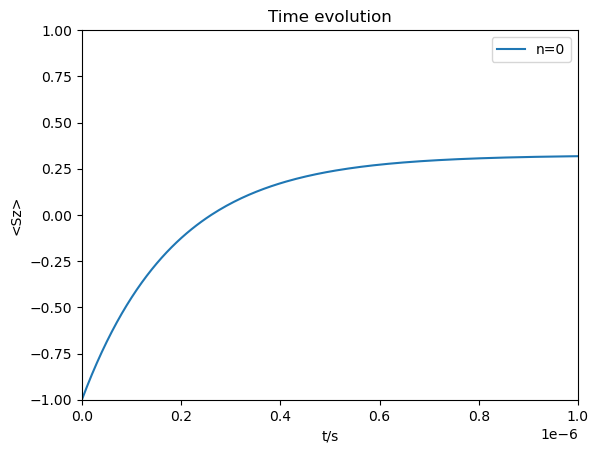

T2=200 s


In [ ]:
# calc and plot time evolution
psi_exc = np.array([0, 1])    # define excited state
lind.calcTimeEvolution(spinsys1, psi_0=psi_exc, timeRange=[0, 1e-6], N_times=200)   # calculate the time evolution for a specific time range and initial state. 
lind.plotTimeEvolution(spinsys1);   # plot the calculated time evolution
print(f'T2={spinsys1.T2} s')    # TODO QUESTION is T2 decay time?? Or what is it in ns??

We see an exponential relaxation of a fully excited spin state towards thermal equilibrium.

Let's try the same thing with `T=0.0001` K and observe the end state. Notice that we need a longer time frame here to capture the whole relaxation process as it is slower for lower temperatures.

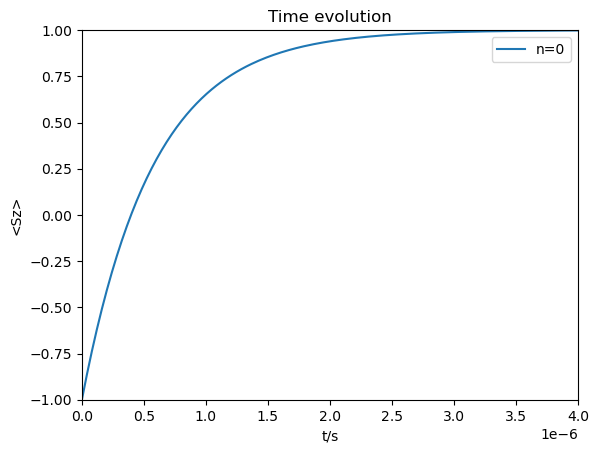

In [5]:
# same thing with very low temperature
spinsys1.T = 0.0001 # K
lind.collapseOperators(spinsys1)
lind.calcTimeEvolution(spinsys1, psi_0=psi_exc, timeRange=[0, 4e-6], N_times=200)
lind.plotTimeEvolution(spinsys1);

For very low temperatures, the spin relaxes towards the ground state. We can now investigate what a different initial state leads to. 

We start in a superposition of the eigenstates and return to `T = 1` K. The relaxation is still exponential but the initial value of < Sz > should be different. For multiple coupled spins, this could result in oscillating behaviour, but for this single-spin case, the main visible difference is the initial condition. The end state is the same as in the previous example with the same temperature.

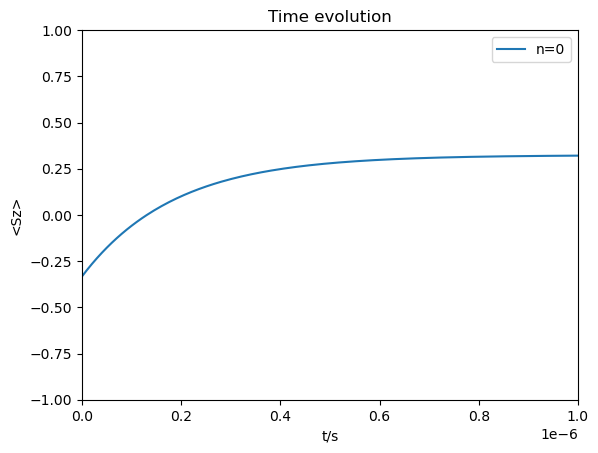

In [ ]:
# higher temperature again but superposition initial state
spinsys1.T = 1
lind.collapseOperators(spinsys1)

psi_mix = np.sqrt(1/3)*np.array([1, 0]) + np.sqrt(2/3)*np.array([0, 1]) # define superposition state
lind.calcTimeEvolution(spinsys1, psi_0=psi_mix, timeRange=[0, 1e-6], N_times=200)
lind.plotTimeEvolution(spinsys1);

### Tip field sweep

We can now plot a tip field sweep using `lind.plotDecayTipfieldsweep` to see if a different behaviour occurs for a non-zero tip field. But our single spin is unfortunately too boring for that. 

In general one needs to be careful when choosing the number of time and BTip field steps (`N_times`and `N_BTip`). The plot can be misleading and mesolve possibly doesn't converge if there are too little steps. On the other hand, increasing the steps also increases the calculation time.

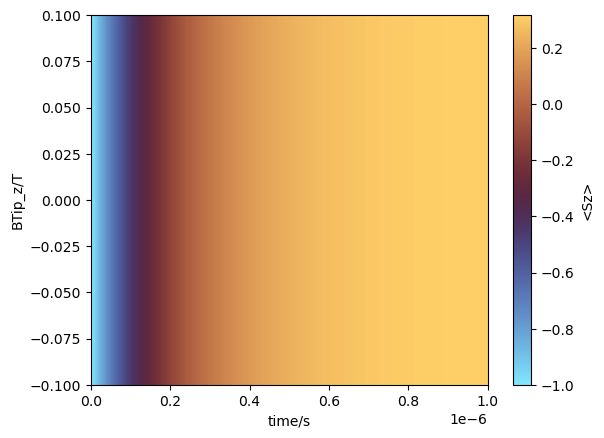

In [9]:
lind.plotDecayTipfieldsweep(spinsys1, psi_0=psi_exc, timeRange = [0, 1e-6], N_times=200, BTipRange = [-0.1, 0.1], N_BTip=200);

## Two coupled spin-1/2

At this point, a new SpinSys object will be initialized. It has a different name but to be sure that no parameters get mixed up, better restart the kernel.

We will have a look at a more dynamic system of two coupled spin-1/2 with B = [0, 0, 0.5] T external field, a tip field of BTip = [0.01, 0, 0.01] T and 0.5 GHz exchange coupling. We can first have a look at the Hamiltonian of the system and plot the eigenmatrix and tip field Zeeman diagram. We will see that with a non-zero tip field, there is a bit of detuning but the eigenstates |1> and |2> are mixed.

In [33]:
# initialize SpinSys object 
spinsys2 = SpinSys([0.5, 0.5])
spinsys2.B = np.array([0, 0, 0.5])  # T
spinsys2.BTip = np.array([0.01, 0, 0.01]) # T
spinsys2.T = 0.3    # K
spinsys2.Jvector[0, :] = np.array([1, 1, 1])*0.5*spinsys2.GHztomeVConversion    # 0.5 GHz exchange coupling

# define tunneling parameters
spinsys2.G_ss = [2e-9]*spinsys2.NSpins 
spinsys2.G=0.2e-9
spinsys2.G_tt = 1
spinsys2.V_DC = 0

# plot EigenMatrix
hamil.calcEigStates(spinsys2)
vis.plotEigenMatrix(spinsys2);
lind.plotTipZeemanDiagramm(spinsys2, BTipRange=[-0.1, 0.1], N_BTip=200);

# calculate Lindblad operators
lind.collapseOperators(spinsys2);

### Time evolution and Fourier transformation

Let's plot the time evolution of the spin system using `lind.calcTimeEvolution` and `lind.calcTimeEvolution` that we already know. For this we set the initial state to [0, 0, 0, 1] (in the spin basis). This is an eigenstate of the Hamiltonian as we know from the eigenmatrix. A density matrix (for example as a numpy 4x4 array) can also be given to the function as the initial state.

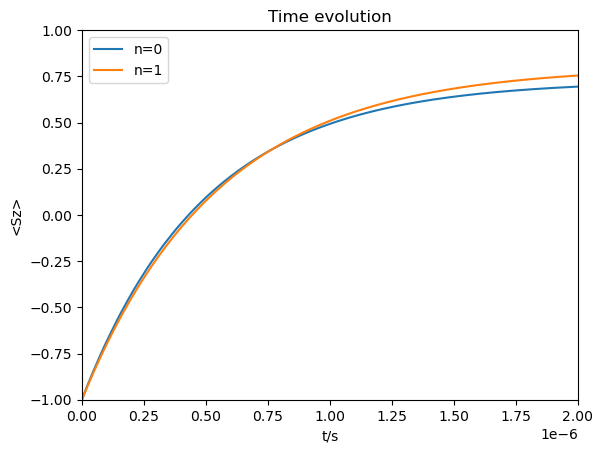

In [89]:
psi_evec = np.array([0, 0, 0, 1])   # excited state (eigenstate)
lind.calcTimeEvolution(spinsys2, psi_evec, timeRange=[0, 2e-6], N_times=200)
lind.plotTimeEvolution(spinsys2);
# TODO difference between both spins here comes from what? Thought only end state is different for spin with BTip influence.
# Thought difference in behaviour of different spins is due to initial state. For no detuning and [0010] both behave the same.

For an eigenstate, one can observe that no oscillations occur.

The next step will be to look at the behaviour for an initial state that is not an eigenstate of the Hamiltonian. For this we can choose [0, 0, 1, 0] which mixes two spin states. Now we expect oscillations of < Sz > (t). We first calculate one time evolution result with too little time steps and then a second result with more steps to see what difference this makes. This last result gets plotted twice, once the full time range and once only spin 0 with a zoom into the first ns. 

None
{'store_states': True, 'nsteps': 1000}


c:\Users\Philip\.conda\envs\library_development\Lib\site-packages\qutip\solver\solver_base.py:598: FutureWarning:

e_ops will be keyword only from qutip 5.3 for all solver

c:\Users\Philip\.conda\envs\library_development\Lib\site-packages\scipy\integrate\_ode.py:418: UserWarning:

_zvode: Excess work done on this call. (Perhaps wrong MF.)



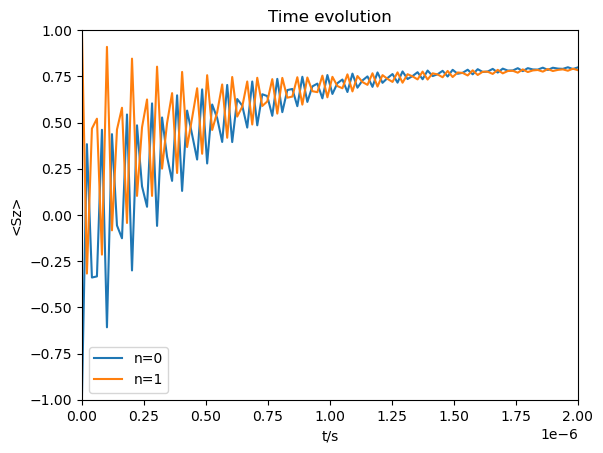

None
{'store_states': True, 'nsteps': 1000}


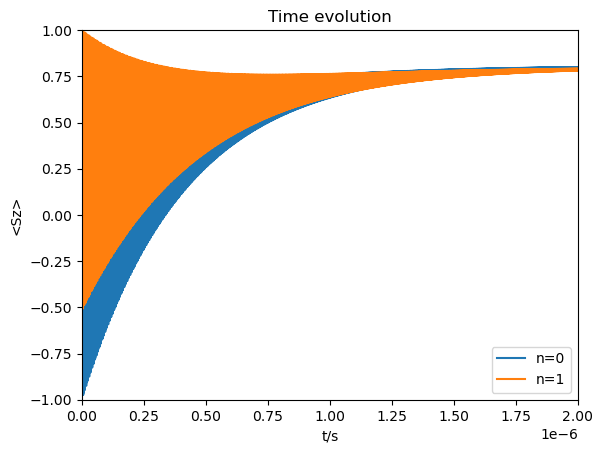

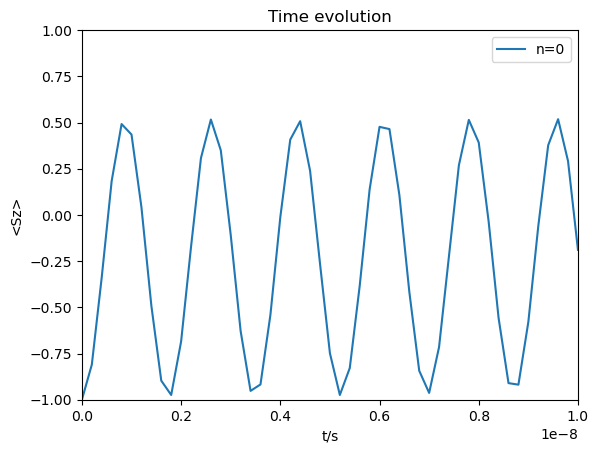

In [56]:
psi_mix = np.array([0, 0, 1, 0])  # define mixed state 

# calculate and plot time evolution
lind.calcTimeEvolution(spinsys2, psi_mix, timeRange=[0, 2e-6], N_times=100)  # calculate the time evolution for few time points for demonstration
lind.plotTimeEvolution(spinsys2);
lind.calcTimeEvolution(spinsys2, psi_mix, timeRange=[0, 2e-6], N_times=10000)    # calculate time evolution for more time points
lind.plotTimeEvolution(spinsys2);   # plot full result
lind.plotTimeEvolution(spinsys2, timeRange=[0, 10e-9], spin_idxToPlot=[0]);    # plot result only for spin 0 and for a specific time range
# TODO comments: amplitude depends on strength of mixing? Frequency on J, D and BTip? 


The result will also be Fourier transformed. Note that for the Fourier peaks to be sharp, the time evolution result has to contain enough oscillation periods. We expect that the main frequency that is present corresponds to the exchange coupling of 500 MHz and some detuning from the tip field. There can also be some contributions from exponential decay. In the zoom in plot just above we see around 5.7 oscillations in 10ns, which corresponds to a frequency of 570 MHz.

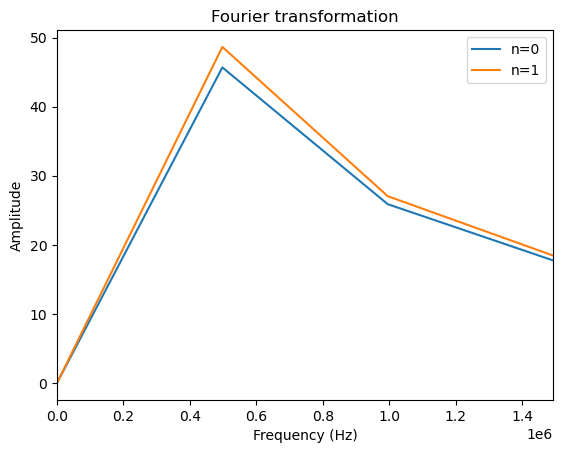

frequencies of the oscillations: 
 spin 0:[0.4975] MHz 
 spin 1:[0.4975] MHz
J=500.0 MHz


In [91]:
# calculate and plot Fourier transformation
mix_freqs = lind.plotFourierFreqs(spinsys2)
freq_peaks = mix_freqs['frequency_peaks']
print(f'frequencies of the oscillations: \n spin 0:{freq_peaks[0]*1e-6} MHz \n spin 1:{freq_peaks[1]*1e-6} MHz')
print(f'J={spinsys2.Jvector[0][0]*spinsys2.meVtoGHzConversion*1e3} MHz')

### Density matrices    

Plot density matrices at specific times in the calculated time evolution result. Takes closest value to time 
see at 0s, after 1/2 oscillation, 1 oscillation and towards the end at 1.5e-6 s. We see that off-diagonals also start oscillating and relaxation towards ground state.
Red bars mean negative value, grey means 0.

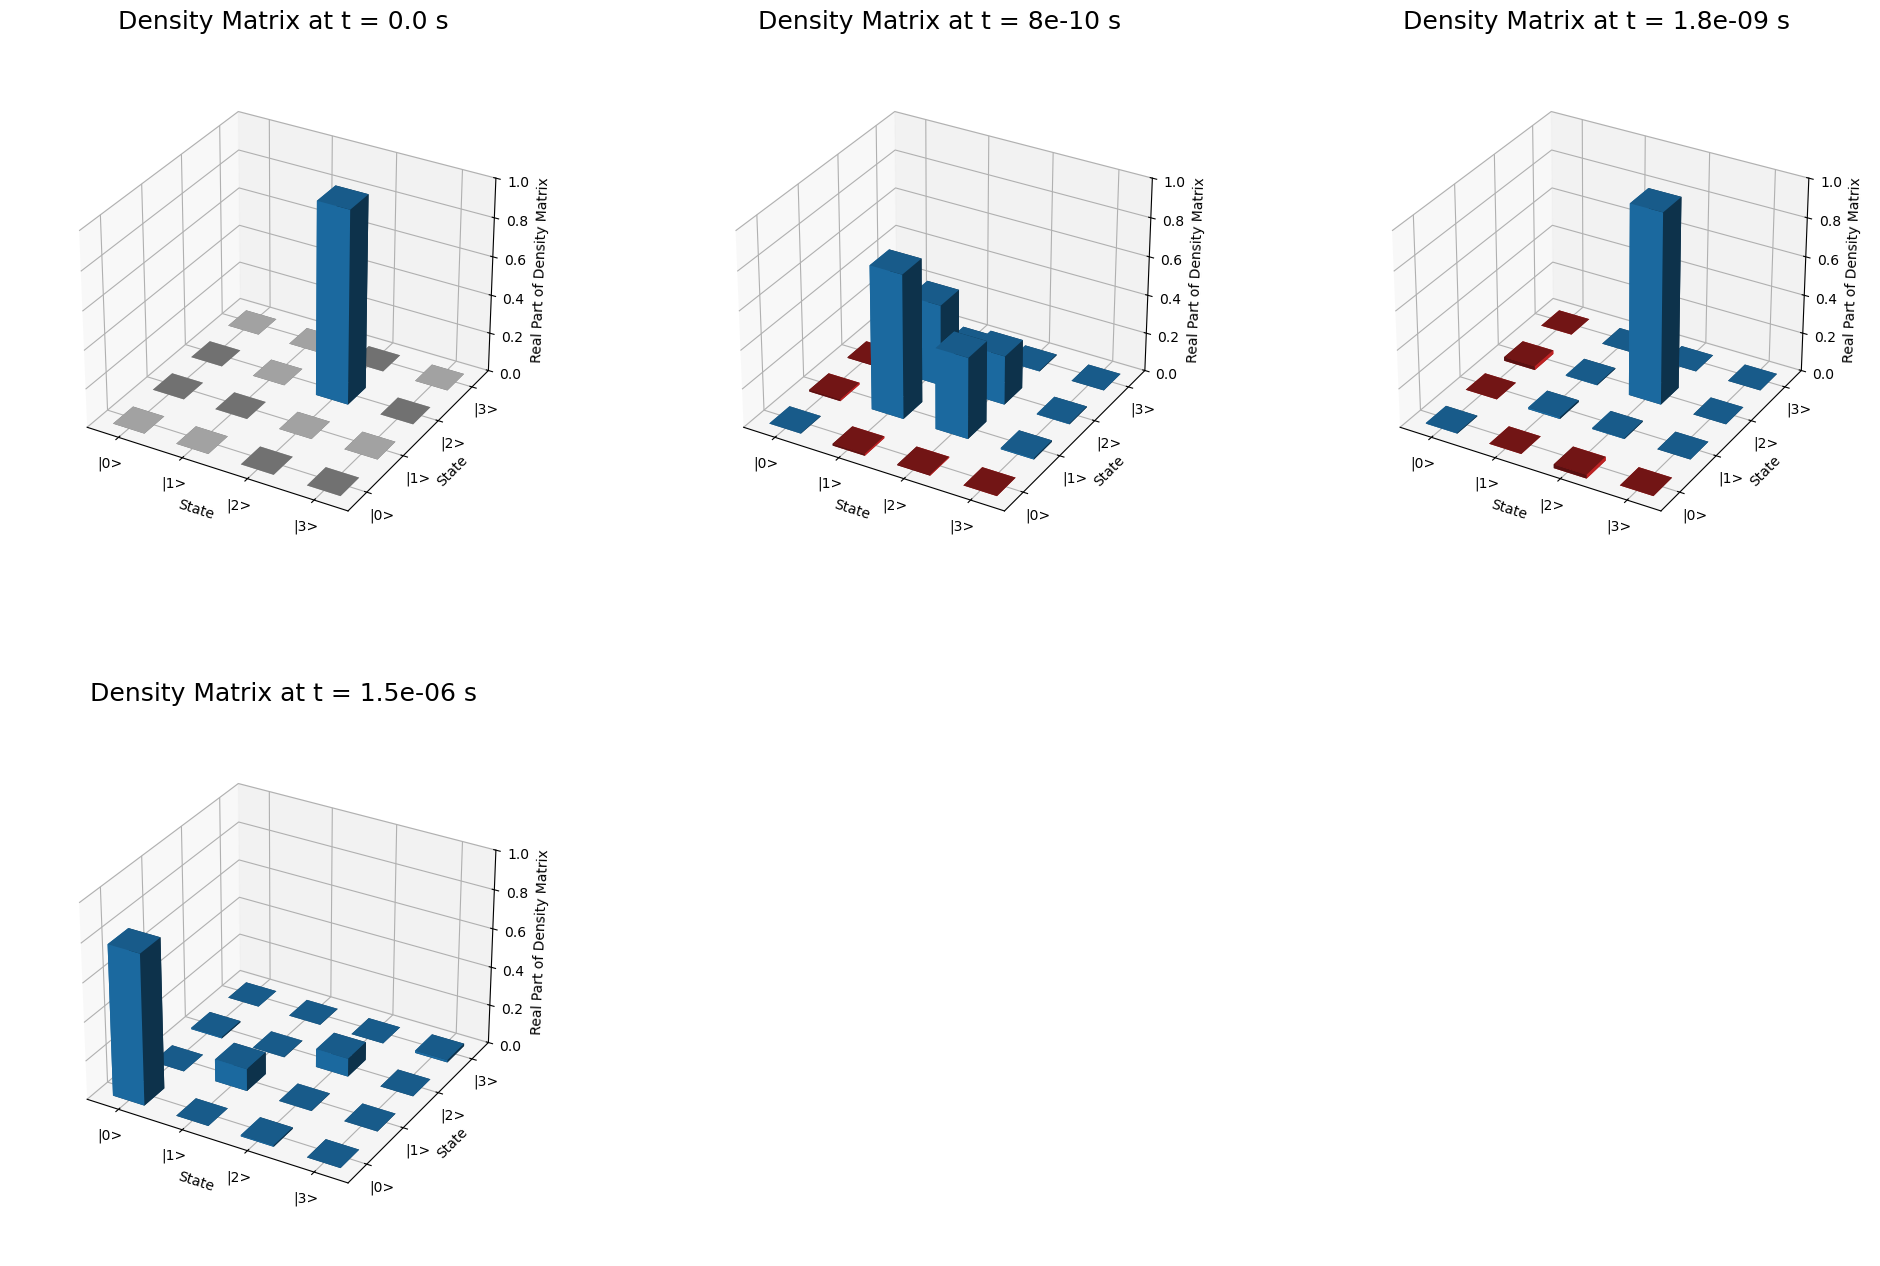

In [79]:
times_densmats = [0, 0.09e-8, 1/574e6, 1.5e-6]
lind.plotDensityMatrix(spinsys2, time_type="value", time_value=times_densmats);
##lind.plotDensityMatrix(spinsys2, time_type="value", time_value=[0, 1]);

### Tip field sweep

And one last tip field sweep...
If you get an IntegratorException, try increasing N_times or increase nsteps through the argument options={'nsteps':1000} (1000 is default).

C:\Users\Philip\Desktop\VSCode\ternes_ldos\spinsimulation\calcBath.py:438: RuntimeWarning:

invalid value encountered in scalar divide

c:\Users\Philip\.conda\envs\library_development\Lib\site-packages\qutip\solver\solver_base.py:598: FutureWarning:

e_ops will be keyword only from qutip 5.3 for all solver



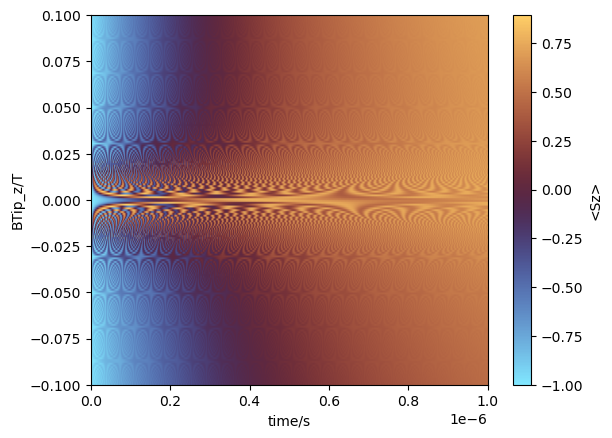

In [90]:
lind.plotDecayTipfieldsweep(spinsys2, psi_0=psi_mix, timeRange = [0, 1e-6], N_times=500, BTipRange = [-0.1, 0.1], N_BTip=200, options={'nsteps':5000});

In [ ]:
lind.plotDecayTipfieldsweep(spinsys2, psi_0=psi_mix, timeRange = [0, 0.5e-6], N_times=500, BTipRange = [-0.1, 0.1], N_BTip=200, options={'nsteps':1000});

C:\Users\Philip\Desktop\VSCode\ternes_ldos\spinsimulation\calcBath.py:438: RuntimeWarning:

invalid value encountered in scalar divide

c:\Users\Philip\.conda\envs\library_development\Lib\site-packages\qutip\solver\solver_base.py:598: FutureWarning:

e_ops will be keyword only from qutip 5.3 for all solver



Still missing: current.